# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [15]:
import pandas as pd
import numpy as np

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [9]:
# 1.1 MAE using scikit-learn
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,mean_absolute_percentage_error,r2_score
def calculate_mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

y_true_example = [3, 5, 2.5, 7]
y_pred_example = [2.5, 5, 4, 8]
print("MAE:", mean_absolute_error(y_true_example, y_pred_example))
    

MAE: 0.75


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [0]:
def calculate_mse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred)
y_true_example = [3, 5, 2.5, 7]
y_pred_example = [2.5, 5, 4, 8]
print("MSE:", mean_squared_error(y_true_example, y_pred_example))


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [0]:
def calculate_rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)
y_true_example = [3, 5, 2.5, 7]
y_pred_example = [2.5, 5, 4, 8]

print("RMSE:", root_mean_squared_error(y_true_example, y_pred_example))


#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [0]:
def calculate_mae(y_true, y_pred):
    return mean_absolute_percentage_error(y_true, y_pred)
y_true_example = [3, 5, 2.5, 7]
y_pred_example = [2.5, 5, 4, 8]
print("MAPE:", mean_absolute_percentage_error(y_true_example, y_pred_example))


#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [0]:
def calculate_r2(y_true, y_pred):
    return r2_score(y_true, y_pred)
y_true_example = [3, 5, 2.5, 7]
y_pred_example = [2.5, 5, 4, 8]
print("R²:", r2_score(y_true_example, y_pred_example))  

### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Read the dataset (the first column is just a row index, so it is used as the index)
advertising = pd.read_csv("advertising.csv", index_col=0)
print("Shape:", advertising.shape)
print("Missing values:", advertising.isna().sum().sum())
advertising.head()

Shape: (200, 4)
Missing values: 0


,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [17]:
advertising.describe().round(3)

,TV,Radio,Newspaper,Sales
count,200.000,200.000,200.000,200.000
mean,147.042,23.264,30.554,14.022
std,85.854,14.847,21.779,5.217
min,0.700,0.000,0.300,1.600
25%,74.375,9.975,12.750,10.375
50%,149.750,22.900,25.750,12.900
75%,218.825,36.525,45.100,17.400
max,296.400,49.600,114.000,27.000


In [ ]:
X = advertising.drop(columns=["Sales"])
y = advertising["Sales"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200, 3)
y shape: (200,)


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

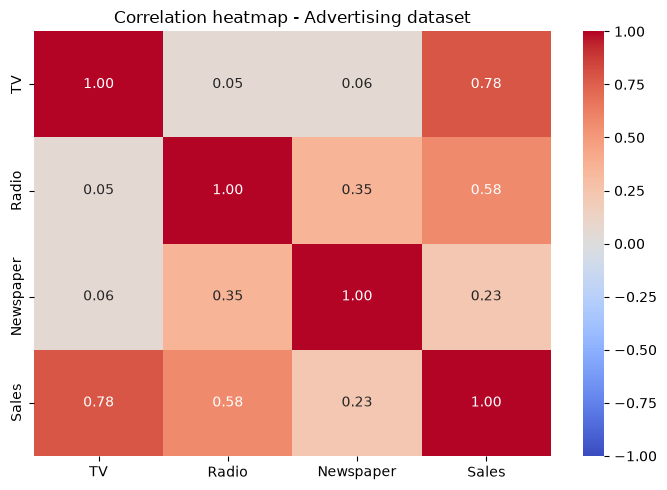

In [20]:

correlation_matrix = advertising.corr()
correlation_matrix.round(3)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap - Advertising dataset")
plt.tight_layout()
plt.show()

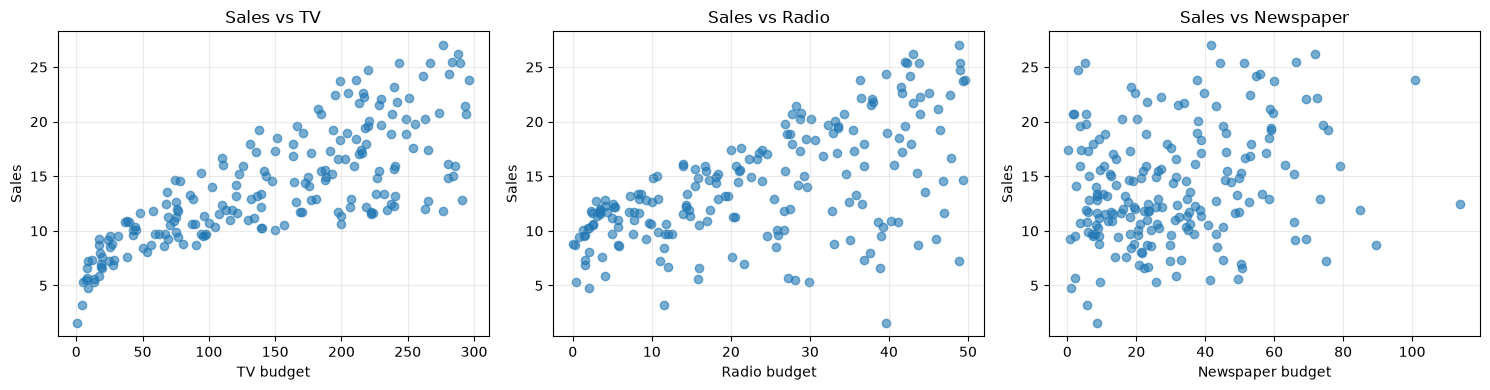

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["TV", "Radio", "Newspaper"]):
    ax.scatter(advertising[col], advertising["Sales"], alpha=0.6)
    ax.set_xlabel(f"{col} budget")
    ax.set_ylabel("Sales")
    ax.set_title(f"Sales vs {col}")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()



**Observations**

- TV has the strongest correlation with Sales (0.78), and its scatter plot shows a clear upward linear trend.
- Radio has a moderate positive correlation with Sales (0.58). The points are more spread out than for TV.
- Newspaper has only a weak correlation with Sales (0.23), and its scatter plot looks like a cloud with little pattern.
- The advertising channels are barely correlated with each other, except Radio and Newspaper (0.35). So multicollinearity is not a big problem here.
- TV and Radio look like useful predictors of Sales, while Newspaper probably adds little.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train mean:", X_train_scaled.mean(axis=0).round(3))
print("Train std:", X_train_scaled.std(axis=0).round(3))

(134, 3) (134,) (66, 3) (66,)
Train mean: [-0. -0.  0.]
Train std: [1. 1. 1.]


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [28]:

from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)
# Fit linear regression model
model.fit(X_train_scaled, y_train)
# Generate predictions
y_pred = model.predict(X_test_scaled)

print("b0 (intercept):", model.intercept_)
print("b1 (coefficients):", model.coef_)

# Coefficients with feature names
pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})

b0 (intercept): 14.022388059701495
b1 (coefficients): [ 3.9675339   2.88155345 -0.07344038]


,Feature,Coefficient
0,TV,3.967534
1,Radio,2.881553
2,Newspaper,-0.073440


#### 2.5 Evaluate created model with above functions

In [30]:
#MAE
def calculate_mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

#MSE
def calculate_mse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred)

# RMSE
def calculate_rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE 
def calculate_mape(y_true, y_pred):
    return mean_absolute_percentage_error(y_true, y_pred) * 100

# R^2
def calculate_r2(y_true, y_pred):
    return r2_score(y_true, y_pred)

# 2.5 Evaluate the linear regression model
print("MAE:", calculate_mae(y_test, y_pred))
print("MSE:", calculate_mse(y_test, y_pred))
print("RMSE:", calculate_rmse(y_test, y_pred))
print("MAPE:", calculate_mape(y_test, y_pred), "%")
print("R^2:", calculate_r2(y_test, y_pred))


MAE: 1.241490259650847
MSE: 3.47262996875279
RMSE: 1.8634993879131783
MAPE: 18.638804594568974 %
R^2: 0.8515370160992792


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [31]:

from sklearn.model_selection import cross_val_score


cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=10, scoring="r2")
print("R^2 for each fold:", cv_scores.round(3))
print("Mean R^2:", cv_scores.mean())

R^2 for each fold: [0.952 0.868 0.923 0.853 0.909 0.869 0.913 0.819 0.93  0.948]
Mean R^2: 0.8982698791408206


The mean R^2 over 10 folds is about 0.90, so the model explains roughly 90% of the variation in Sales on unseen folds. The fold scores are close to each other (0.82 to 0.95), which means the model is stable and not overfitted to one particular split.

#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [36]:

X_reduced = X.drop(columns=["Newspaper"])#Dropped Newspaper (weakest correlation with Sales)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced, y, test_size=0.33, random_state=17)

scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

model_reduced = LinearRegression(fit_intercept=True)
model_reduced.fit(X_train_r_scaled, y_train_r)
y_pred_reduced = model_reduced.predict(X_test_r_scaled)

print("b0 (intercept):", model_reduced.intercept_)
print("b1 (coefficients):", model_reduced.coef_)

# Evaluate the reduced model
print("MAE:", calculate_mae(y_test_r, y_pred_reduced))
print("MSE:", calculate_mse(y_test_r, y_pred_reduced))
print("RMSE:", calculate_rmse(y_test_r, y_pred_reduced))
print("MAPE:", calculate_mape(y_test_r, y_pred_reduced), "%")
print("R^2:", calculate_r2(y_test_r, y_pred_reduced))

cv_scores_r = cross_val_score(model_reduced, X_train_r_scaled, y_train_r, cv=10, scoring="r2")
print("Mean R^2 (10-fold):", cv_scores_r.mean())

b0 (intercept): 14.022388059701495
b1 (coefficients): [3.95954712 2.85961481]
MAE: 1.2423619953941778
MSE: 3.458740998763223
RMSE: 1.859769071353544
MAPE: 18.594637663112877 %
R^2: 0.8521308017736854
Mean R^2 (10-fold): 0.8988465267697936


In [37]:
# Compare both models
comparison = pd.DataFrame({
    "Full model (TV, Radio, Newspaper)": [
        calculate_mae(y_test, y_pred), calculate_mse(y_test, y_pred),
        calculate_rmse(y_test, y_pred), calculate_mape(y_test, y_pred),
        calculate_r2(y_test, y_pred), cv_scores.mean()],
    "Reduced model (TV, Radio)": [
        calculate_mae(y_test_r, y_pred_reduced), calculate_mse(y_test_r, y_pred_reduced),
        calculate_rmse(y_test_r, y_pred_reduced), calculate_mape(y_test_r, y_pred_reduced),
        calculate_r2(y_test_r, y_pred_reduced), cv_scores_r.mean()]},
    index=["MAE", "MSE", "RMSE", "MAPE (%)", "R^2", "Mean CV R^2"])
comparison.round(4)

,"Full model (TV, Radio, Newspaper)","Reduced model (TV, Radio)"
MAE,1.2415,1.2424
MSE,3.4726,3.4587
RMSE,1.8635,1.8598
MAPE (%),18.6388,18.5946
R^2,0.8515,0.8521
Mean CV R^2,0.8983,0.8988


Removing Newspaper does not make the model worse. MSE and R^2 are almost the same, and the reduced model is even very slightly better (MSE 3.4587 vs 3.4726). This agrees with the correlation analysis: Newspaper has a weak link with Sales, so it adds almost no useful information. The simpler model is preferred.

### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [38]:

from sklearn.linear_model import Lasso

lasso = Lasso(alpha=1)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
print("Mean Squared Error:", mse_lasso)
print("Coefficients:", lasso.coef_)

Mean Squared Error: 4.911579294712751
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [39]:

from sklearn.linear_model import Ridge


ridge = Ridge(alpha=1)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
print("Mean Squared Error:", mse_ridge)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.4768894774722394
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [40]:
from sklearn.linear_model import ElasticNet
elastic_net = ElasticNet(alpha=1, l1_ratio=0.5)
elastic_net.fit(X_train_scaled, y_train)

y_pred_en = elastic_net.predict(X_test_scaled)

mse_en = mean_squared_error(y_test, y_pred_en)
print("Mean Squared Error:", mse_en)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 6.8438833201041085
Coefficients: [2.39397459 1.68907463 0.01489489]


#### 3.4 Make conclusions

Elastic Net Regression with alpha=1, l1_ratio=0.5 has the highest MSE (6.84).It combines the L1 and L2 penalties, so the coefficients are shrunk even more than with Lasso or Ridge alone, and the Newspaper coefficient is almost 0. With alpha=1 the penalty is too strong for this data, which leads to underfitting.


## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [42]:
from sklearn.metrics import accuracy_score

def calculate_accuracy(y_true, y_pred):
    return accuracy_score(y_true, y_pred)

y_true_example = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred_example = [1, 0, 0, 1, 0, 1, 1, 0]
print("Accuracy:", calculate_accuracy(y_true_example, y_pred_example))

Accuracy: 0.75


#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [43]:

from sklearn.metrics import precision_score

def calculate_precision(y_true, y_pred):
    return precision_score(y_true, y_pred)

print("Precision:", calculate_precision(y_true_example, y_pred_example))

Precision: 0.75


#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [56]:
from sklearn.metrics import recall_score

def calculate_recall(y_true, y_pred):
    return recall_score(y_true, y_pred)

y_true_example = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred_example = [1, 0, 0, 1, 0, 1, 1, 0]
print("Recall:", calculate_recall(y_true_example, y_pred_example))

Recall: 0.75


#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [44]:
from sklearn.metrics import f1_score

def calculate_f1(y_true, y_pred):
    return f1_score(y_true, y_pred)

y_true_example = [1, 0, 1, 1, 0, 1, 0, 0]
y_pred_example = [1, 0, 0, 1, 0, 1, 1, 0]
print("F1:", calculate_f1(y_true_example, y_pred_example))

F1: 0.75


### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [ ]:
diabetes = pd.read_csv("diabetes.csv")
print("Shape:", diabetes.shape)
diabetes.head()
# In these columns a value of 0 is not possible, so it really means "missing"
zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Zeros before:")
print((diabetes[zero_columns] == 0).sum())
# Replace the zeros with the mean of the column (calculated without the zeros)
diabetes[zero_columns] = diabetes[zero_columns].replace(0, np.nan)
diabetes[zero_columns] = diabetes[zero_columns].fillna(diabetes[zero_columns].mean())

print("Zeros after:", (diabetes[zero_columns] == 0).sum().sum())
print("Missing values:", diabetes.isna().sum().sum())

# Split the data into the target variable and the features
X = diabetes.drop(columns=["Outcome"])
y = diabetes["Outcome"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(y.value_counts())

Shape: (768, 9)
Zeros before:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Zeros after: 0
Missing values: 0
X shape: (768, 8)
y shape: (768,)
Outcome
0    500
1    268
Name: count, dtype: int64


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

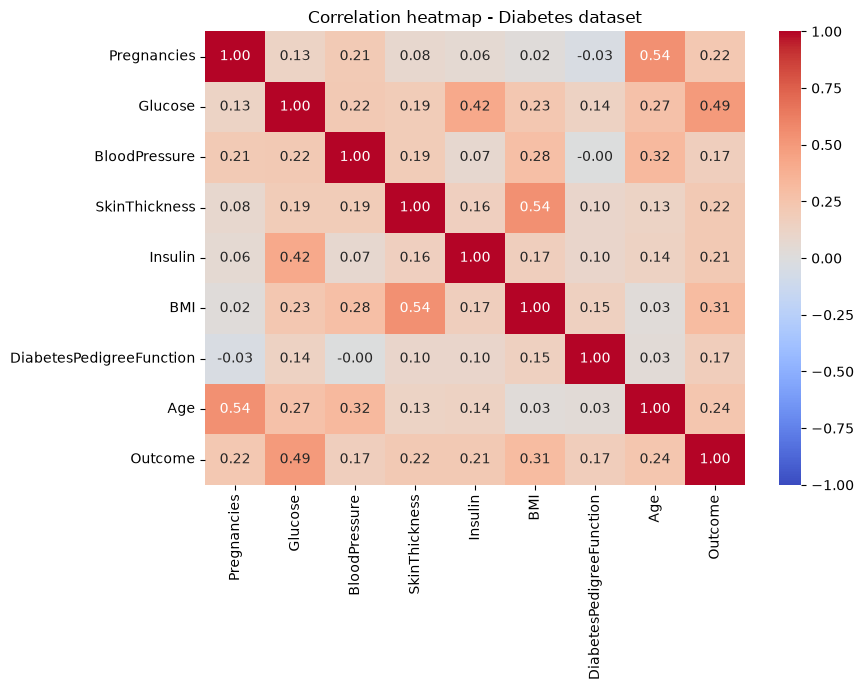

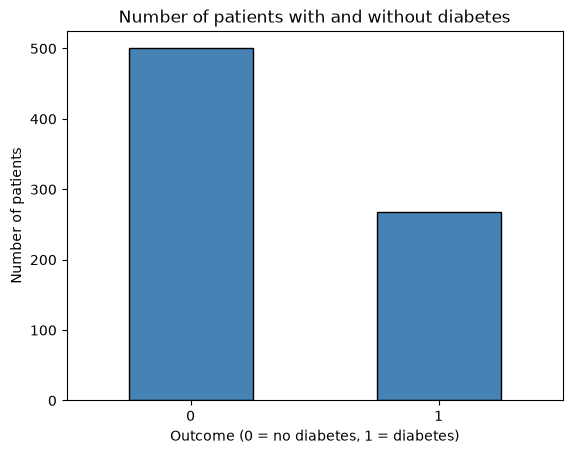

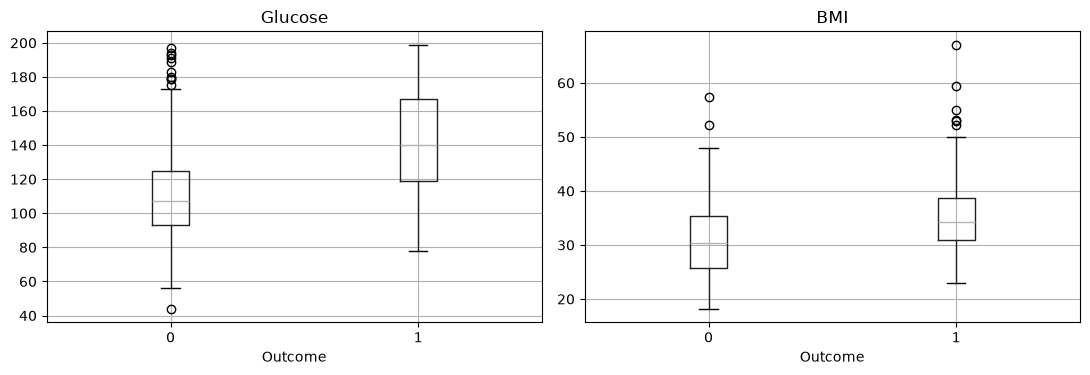

In [49]:
correlation_matrix = diabetes.corr()
correlation_matrix.round(2)
# Correlation heatmap
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heatmap - Diabetes dataset")
plt.tight_layout()
plt.show()

# Class balance
diabetes["Outcome"].value_counts().plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of patients with and without diabetes")
plt.xlabel("Outcome (0 = no diabetes, 1 = diabetes)")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
plt.show()
# Glucose and BMI by outcome
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
diabetes.boxplot(column="Glucose", by="Outcome", ax=axes[0])
diabetes.boxplot(column="BMI", by="Outcome", ax=axes[1])
fig.suptitle("")
plt.tight_layout()
plt.show()

Glucose has the strongest link with the outcome (0.49), and the boxplot shows that patients with diabetes have clearly higher glucose levels. BMI is next (0.31), then age (0.24). The other features are weaker, around 0.17 to 0.22. Among the features themselves, the biggest correlations are age with pregnancies (0.54), skin thickness with BMI (0.54) and glucose with insulin (0.42), which makes sense medically. The classes are not balanced, about 65% of patients have no diabetes, so accuracy alone can look better than the model really is.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [50]:
# Split the data 2:1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
# Scale the features (fit on the training set only, then apply to the test set)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

(514, 8) (514,) (254, 8) (254,)


#### 2.4 Fit logistic regression model, generate predictions

In [53]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train_scaled, y_train)

y_pred_log = logreg.predict(X_test_scaled)
y_pred_log[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 2.5 Create a confusion matrix and evaluate created model with above functions

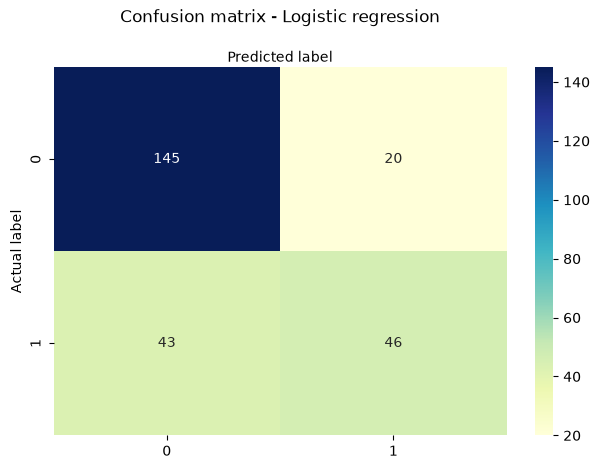

Accuracy: 0.7519685039370079
Precision: 0.696969696969697
Recall: 0.5168539325842697
F1: 0.5935483870967742


In [57]:
from sklearn.metrics import confusion_matrix
# Confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred_log)
cnf_matrix
# Visualize the confusion matrix
class_names = [0, 1]
fig, ax = plt.subplots()
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt="g",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.xaxis.set_label_position("top")
plt.title("Confusion matrix - Logistic regression", y=1.1)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

# Evaluation
print("Accuracy:", calculate_accuracy(y_test, y_pred_log))
print("Precision:", calculate_precision(y_test, y_pred_log))
print("Recall:", calculate_recall(y_test, y_pred_log))
print("F1:", calculate_f1(y_test, y_pred_log))


The model gets about 75% of the patients right. Precision is 0.70, so when it says a patient has diabetes it is right 7 times out of 10. Recall is only 0.52, which means it misses almost half of the real diabetes cases (43 patients were missed). That is the weak point of this model, because in a medical problem missing a sick patient is worse than a false alarm.

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8311201906707525


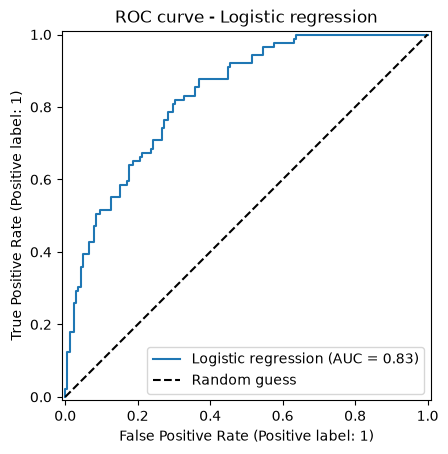

In [61]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import RocCurveDisplay

y_proba_log = logreg.predict_proba(X_test_scaled)[:, 1]

auc_log = roc_auc_score(y_test, y_proba_log)
print("AUC:", auc_log)

RocCurveDisplay.from_predictions(y_test, y_proba_log, name="Logistic regression")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.title("ROC curve - Logistic regression")
plt.show()

The AUC is about 0.83, which is a good result. The curve stays well above the diagonal line, so the model separates patients with and without diabetes much better than random guessing.

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [62]:
cv_scores_log = cross_val_score(logreg, X_train_scaled, y_train, cv=10, scoring="accuracy")
print("Accuracy for each fold:", cv_scores_log.round(3))
print("Mean accuracy:", cv_scores_log.mean())

Accuracy for each fold: [0.692 0.827 0.788 0.731 0.706 0.765 0.882 0.725 0.725 0.804]
Mean accuracy: 0.764630467571644


The mean accuracy over the 10 folds is about 0.76, very close to the 0.75 on the holdout set. So the result is stable and the model is not overfitted.

### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [63]:
from sklearn.tree import DecisionTreeClassifier


clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred_clf = clf.predict(X_test_scaled)
y_pred_clf[:10]

array([0, 1, 0, 0, 0, 0, 0, 1, 1, 1])

#### 3.2 Evaluate created model with above functions

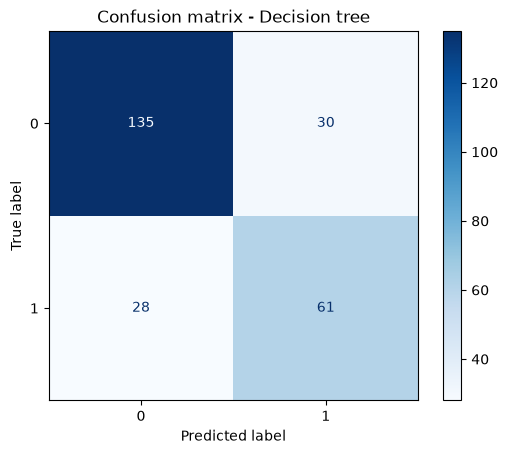

Accuracy: 0.7716535433070866
Precision: 0.6703296703296703
Recall: 0.6853932584269663
F1: 0.6777777777777778


In [65]:

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_clf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap="Blues")
disp.ax_.set_title("Confusion matrix - Decision tree")
plt.show()

print("Accuracy:", calculate_accuracy(y_test, y_pred_clf))
print("Precision:", calculate_precision(y_test, y_pred_clf))
print("Recall:", calculate_recall(y_test, y_pred_clf))
print("F1:", calculate_f1(y_test, y_pred_clf))

The tree reaches about 77% accuracy, slightly more than logistic regression. Its precision is a bit lower (0.67) but recall is much better (0.69), so it finds more of the real diabetes cases (61 compared to 46) at the cost of more false alarms (30 compared to 20). Its F1 (0.68) is clearly higher than for logistic regression (0.59).

#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.7517875383043923


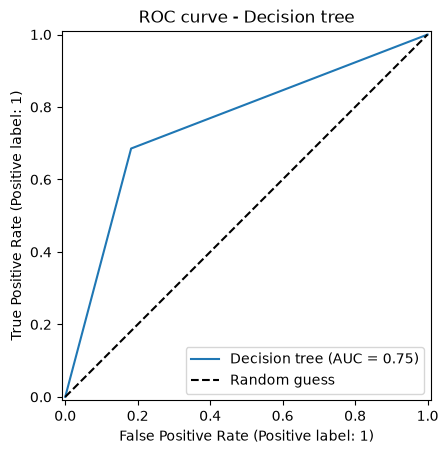

In [66]:
y_proba_clf = clf.predict_proba(X_test_scaled)[:, 1]

auc_clf = roc_auc_score(y_test, y_proba_clf)
print("AUC:", auc_clf)

RocCurveDisplay.from_predictions(y_test, y_proba_clf, name="Decision tree")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.title("ROC curve - Decision tree")
plt.show()

The AUC is about 0.75, which is lower than for logistic regression (0.83). The curve looks like a few big steps because a fully grown tree only gives probabilities like 0 or 1, so it can't rank the patients as smoothly.

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [67]:
cv_scores_clf = cross_val_score(clf, X_train_scaled, y_train, cv=10, scoring="accuracy")
print("Accuracy for each fold:", cv_scores_clf.round(3))
print("Mean accuracy:", cv_scores_clf.mean())

Accuracy for each fold: [0.635 0.731 0.75  0.692 0.667 0.725 0.902 0.667 0.667 0.824]
Mean accuracy: 0.725867269984917


#### 3.5 Make conclusions

In [68]:
comparison_clf = pd.DataFrame({
    "Logistic regression": [
        calculate_accuracy(y_test, y_pred_log), calculate_precision(y_test, y_pred_log),
        calculate_recall(y_test, y_pred_log), calculate_f1(y_test, y_pred_log),
        auc_log, cv_scores_log.mean()],
    "Decision tree": [
        calculate_accuracy(y_test, y_pred_clf), calculate_precision(y_test, y_pred_clf),
        calculate_recall(y_test, y_pred_clf), calculate_f1(y_test, y_pred_clf),
        auc_clf, cv_scores_clf.mean()]},
    index=["Accuracy", "Precision", "Recall", "F1", "AUC", "Mean CV accuracy"])
comparison_clf.round(3)

,Logistic regression,Decision tree
Accuracy,0.752,0.772
Precision,0.697,0.670
Recall,0.517,0.685
F1,0.594,0.678
AUC,0.831,0.752
Mean CV accuracy,0.765,0.726


Both models are fairly close, but they behave differently. Logistic regression has the better AUC (0.83 vs 0.75) and the better CV accuracy (0.76 vs 0.73), so it is the more reliable and stable model. The decision tree looks slightly better on the holdout set (77% vs 75% accuracy), and its recall is much higher (0.69 vs 0.52), so it finds more of the patients who really have diabetes. But its cross-validation score is lower, so that holdout result is probably partly luck, and a tree that is grown fully tends to overfit.

Since this is a medical problem, missing a sick patient is worse than a false alarm, so recall matters a lot. Logistic regression would be my overall choice because it is more stable and ranks patients better, but with its default threshold it misses too many cases. Lowering the decision threshold or limiting the tree depth (for example with max_depth) would be the next things to try. Also, about 65% of the patients have no diabetes, so accuracy alone is not enough and precision, recall and F1 should be read together.